## Loading the Dataset and all required libraries

In [1]:
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OrdinalEncoder, OneHotEncoder
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.linear_model import Ridge, Lasso, ElasticNet
from sklearn.svm import SVR
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, VotingRegressor, BaggingRegressor
from xgboost import XGBRegressor
from sklearn.metrics import mean_absolute_error, r2_score, mean_squared_error
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV, KFold

In [2]:
df_train = pd.read_csv('data/train.csv')

In [3]:
df_test = pd.read_csv('data/test.csv')

## Inspecting data and feature engineering


In [4]:
df_train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   object 
 3   LotFrontage    1201 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   object 
 6   Alley          91 non-null     object 
 7   LotShape       1460 non-null   object 
 8   LandContour    1460 non-null   object 
 9   Utilities      1460 non-null   object 
 10  LotConfig      1460 non-null   object 
 11  LandSlope      1460 non-null   object 
 12  Neighborhood   1460 non-null   object 
 13  Condition1     1460 non-null   object 
 14  Condition2     1460 non-null   object 
 15  BldgType       1460 non-null   object 
 16  HouseStyle     1460 non-null   object 
 17  OverallQual    1460 non-null   int64  
 18  OverallC

In [5]:
df_test.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1459 entries, 0 to 1458
Data columns (total 80 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1459 non-null   int64  
 1   MSSubClass     1459 non-null   int64  
 2   MSZoning       1455 non-null   object 
 3   LotFrontage    1232 non-null   float64
 4   LotArea        1459 non-null   int64  
 5   Street         1459 non-null   object 
 6   Alley          107 non-null    object 
 7   LotShape       1459 non-null   object 
 8   LandContour    1459 non-null   object 
 9   Utilities      1457 non-null   object 
 10  LotConfig      1459 non-null   object 
 11  LandSlope      1459 non-null   object 
 12  Neighborhood   1459 non-null   object 
 13  Condition1     1459 non-null   object 
 14  Condition2     1459 non-null   object 
 15  BldgType       1459 non-null   object 
 16  HouseStyle     1459 non-null   object 
 17  OverallQual    1459 non-null   int64  
 18  OverallC

In [6]:
df_train.head()

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


In [7]:
df_train.shape

(1460, 81)

In [8]:
df_train['MSSubClass'].value_counts()

MSSubClass
20     536
60     299
50     144
120     87
30      69
160     63
70      60
80      58
90      52
190     30
85      20
75      16
45      12
180     10
40       4
Name: count, dtype: int64

In [9]:
df_train['MSSubClass'] = df_train['MSSubClass'].astype('object')
df_test['MSSubClass'] = df_test['MSSubClass'].astype('object')

In [10]:
df_train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   object 
 2   MSZoning       1460 non-null   object 
 3   LotFrontage    1201 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   object 
 6   Alley          91 non-null     object 
 7   LotShape       1460 non-null   object 
 8   LandContour    1460 non-null   object 
 9   Utilities      1460 non-null   object 
 10  LotConfig      1460 non-null   object 
 11  LandSlope      1460 non-null   object 
 12  Neighborhood   1460 non-null   object 
 13  Condition1     1460 non-null   object 
 14  Condition2     1460 non-null   object 
 15  BldgType       1460 non-null   object 
 16  HouseStyle     1460 non-null   object 
 17  OverallQual    1460 non-null   int64  
 18  OverallC

<Axes: >

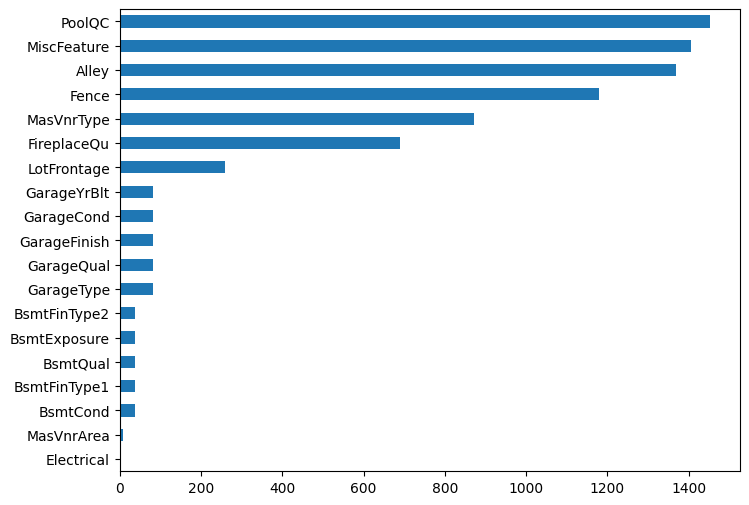

In [11]:
miss = df_train.isna().sum()
miss[miss > 0].sort_values().plot.barh(figsize=(8,6))

In [12]:
df_train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   object 
 2   MSZoning       1460 non-null   object 
 3   LotFrontage    1201 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   object 
 6   Alley          91 non-null     object 
 7   LotShape       1460 non-null   object 
 8   LandContour    1460 non-null   object 
 9   Utilities      1460 non-null   object 
 10  LotConfig      1460 non-null   object 
 11  LandSlope      1460 non-null   object 
 12  Neighborhood   1460 non-null   object 
 13  Condition1     1460 non-null   object 
 14  Condition2     1460 non-null   object 
 15  BldgType       1460 non-null   object 
 16  HouseStyle     1460 non-null   object 
 17  OverallQual    1460 non-null   int64  
 18  OverallC

In [13]:
df_train.describe()

,Id,LotFrontage,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,MasVnrArea,BsmtFinSF1,BsmtFinSF2,...,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,MiscVal,MoSold,YrSold,SalePrice
count,1460.000000,1201.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1452.000000,1460.000000,1460.000000,...,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000
mean,730.500000,70.049958,10516.828082,6.099315,5.575342,1971.267808,1984.865753,103.685262,443.639726,46.549315,...,94.244521,46.660274,21.954110,3.409589,15.060959,2.758904,43.489041,6.321918,2007.815753,180921.195890
std,421.610009,24.284752,9981.264932,1.382997,1.112799,30.202904,20.645407,181.066207,456.098091,161.319273,...,125.338794,66.256028,61.119149,29.317331,55.757415,40.177307,496.123024,2.703626,1.328095,79442.502883
min,1.000000,21.000000,1300.000000,1.000000,1.000000,1872.000000,1950.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,2006.000000,34900.000000
25%,365.750000,59.000000,7553.500000,5.000000,5.000000,1954.000000,1967.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,5.000000,2007.000000,129975.000000
50%,730.500000,69.000000,9478.500000,6.000000,5.000000,1973.000000,1994.000000,0.000000,383.500000,0.000000,...,0.000000,25.000000,0.000000,0.000000,0.000000,0.000000,0.000000,6.000000,2008.000000,163000.000000
75%,1095.250000,80.000000,11601.500000,7.000000,6.000000,2000.000000,2004.000000,166.000000,712.250000,0.000000,...,168.000000,68.000000,0.000000,0.000000,0.000000,0.000000,0.000000,8.000000,2009.000000,214000.000000
max,1460.000000,313.000000,215245.000000,10.000000,9.000000,2010.000000,2010.000000,1600.000000,5644.000000,1474.000000,...,857.000000,547.000000,552.000000,508.000000,480.000000,738.000000,15500.000000,12.000000,2010.000000,755000.000000


In [14]:
pd.set_option('display.max_rows',None)
df_train.isna().sum()

Id                  0
MSSubClass          0
MSZoning            0
LotFrontage       259
LotArea             0
Street              0
Alley            1369
LotShape            0
LandContour         0
Utilities           0
LotConfig           0
LandSlope           0
Neighborhood        0
Condition1          0
Condition2          0
BldgType            0
HouseStyle          0
OverallQual         0
OverallCond         0
YearBuilt           0
YearRemodAdd        0
RoofStyle           0
RoofMatl            0
Exterior1st         0
Exterior2nd         0
MasVnrType        872
MasVnrArea          8
ExterQual           0
ExterCond           0
Foundation          0
BsmtQual           37
BsmtCond           37
BsmtExposure       38
BsmtFinType1       37
BsmtFinSF1          0
BsmtFinType2       38
BsmtFinSF2          0
BsmtUnfSF           0
TotalBsmtSF         0
Heating             0
HeatingQC           0
CentralAir          0
Electrical          1
1stFlrSF            0
2ndFlrSF            0
LowQualFin

In [15]:
df_train.shape

(1460, 81)

In [16]:
df_train.corr(numeric_only=True)['SalePrice']

Id              -0.021917
LotFrontage      0.351799
LotArea          0.263843
OverallQual      0.790982
OverallCond     -0.077856
YearBuilt        0.522897
YearRemodAdd     0.507101
MasVnrArea       0.477493
BsmtFinSF1       0.386420
BsmtFinSF2      -0.011378
BsmtUnfSF        0.214479
TotalBsmtSF      0.613581
1stFlrSF         0.605852
2ndFlrSF         0.319334
LowQualFinSF    -0.025606
GrLivArea        0.708624
BsmtFullBath     0.227122
BsmtHalfBath    -0.016844
FullBath         0.560664
HalfBath         0.284108
BedroomAbvGr     0.168213
KitchenAbvGr    -0.135907
TotRmsAbvGrd     0.533723
Fireplaces       0.466929
GarageYrBlt      0.486362
GarageCars       0.640409
GarageArea       0.623431
WoodDeckSF       0.324413
OpenPorchSF      0.315856
EnclosedPorch   -0.128578
3SsnPorch        0.044584
ScreenPorch      0.111447
PoolArea         0.092404
MiscVal         -0.021190
MoSold           0.046432
YrSold          -0.028923
SalePrice        1.000000
Name: SalePrice, dtype: float64

## Adding features and converting less occuring catagories into other

In [17]:
def add_features(df):
    df = df.copy()
    df['TotalSF'] = df['TotalBsmtSF'] + df['1stFlrSF'] + df['2ndFlrSF']
    df['TotalBath'] = (df['FullBath'] + 0.5*df['HalfBath']
                       + df['BsmtFullBath'] + 0.5*df['BsmtHalfBath'])
    df['TotalPorchSF'] = (df['OpenPorchSF'] + df['EnclosedPorch']
                          + df['3SsnPorch'] + df['ScreenPorch'] + df['WoodDeckSF'])
    df['HouseAge'] = (df['YrSold'] - df['YearBuilt']).clip(lower=0)
    df['RemodAge'] = (df['YrSold'] - df['YearRemodAdd']).clip(lower=0)
    df['IsRemodeled'] = (df['YearRemodAdd'] != df['YearBuilt']).astype(int)
    df['HasGarage'] = (df['GarageArea'] > 0).astype(int)
    df['HasBsmt'] = (df['TotalBsmtSF'] > 0).astype(int)
    df['Has2ndFloor'] = (df['2ndFlrSF'] > 0).astype(int)
    df['HasFireplace'] = (df['Fireplaces'] > 0).astype(int)
    df['HasPool'] = (df['PoolArea'] > 0).astype(int)
    df['MSSubClass'] = df['MSSubClass'].astype(str)
    return df

In [18]:
df_train = add_features(df_train)
df_test = add_features(df_test)

In [19]:
none_cols = ['Alley','BsmtQual','BsmtCond','BsmtExposure','BsmtFinType1','BsmtFinType2',
             'FireplaceQu','GarageType','GarageFinish','GarageCond',
             'PoolQC','Fence','MiscFeature','MasVnrType']
for d in (df_train, df_test):
    d[none_cols] = d[none_cols].fillna('None')
    d['GarageYrBlt'] = d['GarageYrBlt'].fillna(0)

In [20]:
df_train = df_train[~((df_train['GrLivArea'] > 4000) & (df_train['SalePrice'] < 300000))]
X = df_train.drop(columns=['SalePrice', 'Id', 'PoolArea', 'HasPool'])
y = df_train['SalePrice']

In [21]:
X.isna().sum()

MSSubClass         0
MSZoning           0
LotFrontage      259
LotArea            0
Street             0
Alley              0
LotShape           0
LandContour        0
Utilities          0
LotConfig          0
LandSlope          0
Neighborhood       0
Condition1         0
Condition2         0
BldgType           0
HouseStyle         0
OverallQual        0
OverallCond        0
YearBuilt          0
YearRemodAdd       0
RoofStyle          0
RoofMatl           0
Exterior1st        0
Exterior2nd        0
MasVnrType         0
MasVnrArea         8
ExterQual          0
ExterCond          0
Foundation         0
BsmtQual           0
BsmtCond           0
BsmtExposure       0
BsmtFinType1       0
BsmtFinSF1         0
BsmtFinType2       0
BsmtFinSF2         0
BsmtUnfSF          0
TotalBsmtSF        0
Heating            0
HeatingQC          0
CentralAir         0
Electrical         1
1stFlrSF           0
2ndFlrSF           0
LowQualFinSF       0
GrLivArea          0
BsmtFullBath       0
BsmtHalfBath 

In [22]:
numeric_cols =  X.select_dtypes(include=['int64', 'float64']).columns
cat_cols = X.select_dtypes(include=['object']).columns

In [23]:
X[numeric_cols].isna().sum()

LotFrontage      259
LotArea            0
OverallQual        0
OverallCond        0
YearBuilt          0
YearRemodAdd       0
MasVnrArea         8
BsmtFinSF1         0
BsmtFinSF2         0
BsmtUnfSF          0
TotalBsmtSF        0
1stFlrSF           0
2ndFlrSF           0
LowQualFinSF       0
GrLivArea          0
BsmtFullBath       0
BsmtHalfBath       0
FullBath           0
HalfBath           0
BedroomAbvGr       0
KitchenAbvGr       0
TotRmsAbvGrd       0
Fireplaces         0
GarageYrBlt        0
GarageCars         0
GarageArea         0
WoodDeckSF         0
OpenPorchSF        0
EnclosedPorch      0
3SsnPorch          0
ScreenPorch        0
MiscVal            0
MoSold             0
YrSold             0
TotalSF            0
TotalBath          0
TotalPorchSF       0
HouseAge           0
RemodAge           0
IsRemodeled        0
HasGarage          0
HasBsmt            0
Has2ndFloor        0
HasFireplace       0
dtype: int64

In [24]:
X[cat_cols].isna().sum()

MSSubClass        0
MSZoning          0
Street            0
Alley             0
LotShape          0
LandContour       0
Utilities         0
LotConfig         0
LandSlope         0
Neighborhood      0
Condition1        0
Condition2        0
BldgType          0
HouseStyle        0
RoofStyle         0
RoofMatl          0
Exterior1st       0
Exterior2nd       0
MasVnrType        0
ExterQual         0
ExterCond         0
Foundation        0
BsmtQual          0
BsmtCond          0
BsmtExposure      0
BsmtFinType1      0
BsmtFinType2      0
Heating           0
HeatingQC         0
CentralAir        0
Electrical        1
KitchenQual       0
Functional        0
FireplaceQu       0
GarageType        0
GarageFinish      0
GarageQual       81
GarageCond        0
PavedDrive        0
PoolQC            0
Fence             0
MiscFeature       0
SaleType          0
SaleCondition     0
dtype: int64

## Dropping columns which have nearly all constant features


In [25]:
cat_cols = list(cat_cols)
for col in cat_cols:
    share = X[col].value_counts(normalize=True).iloc[0]   
    if share > 0.95:
        print(col, round(share, 3))
        df_train.drop(columns=[col], inplace=True)
        df_test.drop(columns=[col], inplace=True)
        X.drop(columns=[col], inplace=True)
        cat_cols.remove(col)
        

Street 0.996
Utilities 0.999
Condition2 0.99
RoofMatl 0.983
Heating 0.978
GarageQual 0.951
PoolQC 0.996
MiscFeature 0.963


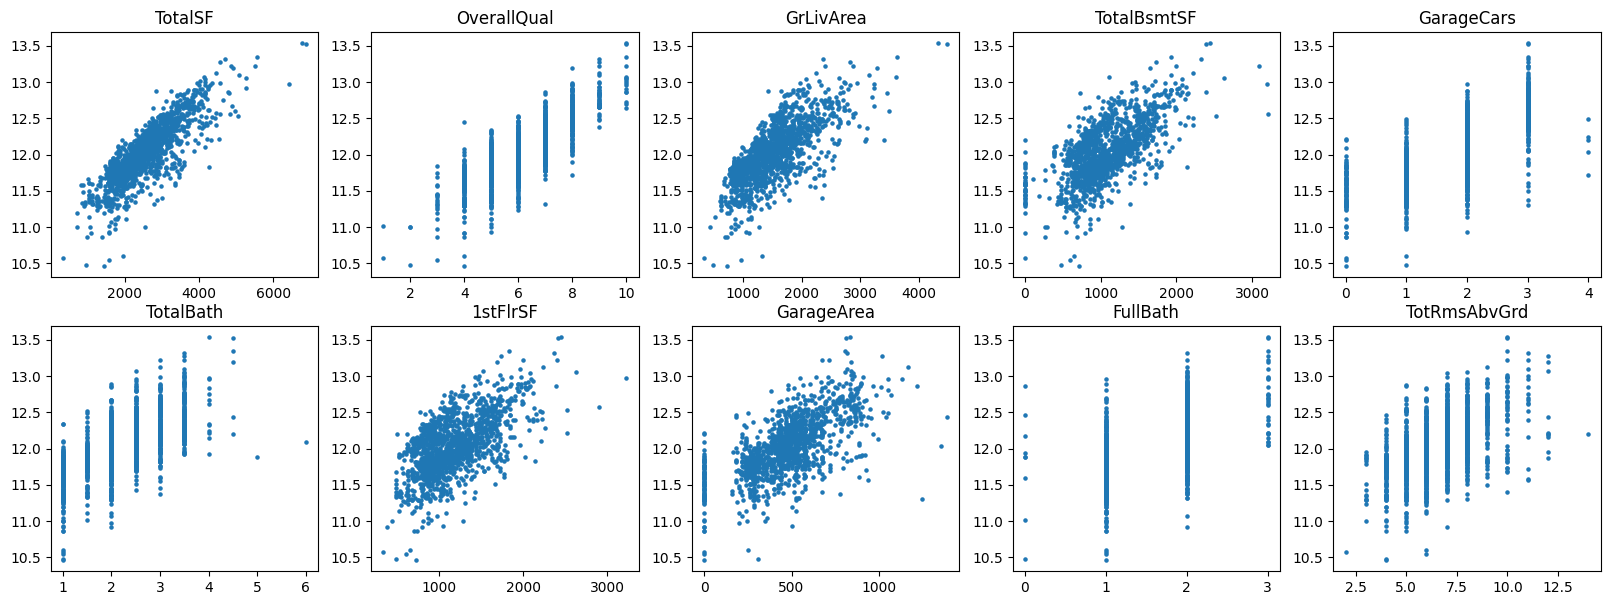

In [26]:
corr = df_train.corr(numeric_only=True)['SalePrice'].drop('SalePrice')
top = corr.abs().sort_values(ascending=False).head(10).index
fig, axes = plt.subplots(2, 5, figsize=(20, 7))
for ax, col in zip(axes.ravel(), top):
    ax.scatter(df_train[col], np.log(df_train['SalePrice']), s=5)
    ax.set_title(col)

In [27]:
cat_cols

['MSSubClass',
 'MSZoning',
 'Alley',
 'LotShape',
 'LandContour',
 'LotConfig',
 'LandSlope',
 'Neighborhood',
 'Condition1',
 'BldgType',
 'HouseStyle',
 'RoofStyle',
 'Exterior1st',
 'Exterior2nd',
 'MasVnrType',
 'ExterQual',
 'ExterCond',
 'Foundation',
 'BsmtQual',
 'BsmtCond',
 'BsmtExposure',
 'BsmtFinType1',
 'BsmtFinType2',
 'HeatingQC',
 'CentralAir',
 'Electrical',
 'KitchenQual',
 'Functional',
 'FireplaceQu',
 'GarageType',
 'GarageFinish',
 'GarageCond',
 'PavedDrive',
 'Fence',
 'SaleType',
 'SaleCondition']

## Spliting catagorical columns into ordinal columns and nominal columns 

In [28]:
ordinal_cols = [col for col in cat_cols if any(q in col for q in ['Qual', 'Qu', 'QC'])]
nominal_cols = [col for col in cat_cols if col not in ordinal_cols]

from sklearn.preprocessing import FunctionTransformer

skew = X[numeric_cols].skew().abs()
skewed_cols = [c for c in skew[skew > 0.75].index
               if X[c].min() >= 0 and not c.startswith(('Has', 'Is', 'Year'))]
normal_cols = [c for c in numeric_cols if c not in skewed_cols]

In [29]:
X['ExterQual'].value_counts(normalize=True).iloc[0]

np.float64(0.6213991769547325)

## Constructing Pipeline and Column Transformer 

In [30]:
numeric_trnf = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

encoding = ColumnTransformer(transformers=[
    ('oe', OrdinalEncoder(categories=[['None', 'Po', 'Fa', 'TA', 'Gd', 'Ex']]*len(ordinal_cols)), ordinal_cols),
    ('ohe', OneHotEncoder(sparse_output=False,
                      handle_unknown='infrequent_if_exist',
                      min_frequency=20), nominal_cols)
], remainder='passthrough')

cat_trnf = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', encoding)
])

skew_trnf = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('log', FunctionTransformer(np.log1p, feature_names_out='one-to-one')),
    ('scaler', StandardScaler())
])

preprocessing = ColumnTransformer(transformers=[
    ('numeric_trnf', numeric_trnf, normal_cols),
    ('skew_trnf', skew_trnf, skewed_cols),
    ('cat_trnf', cat_trnf, cat_cols)
]
)

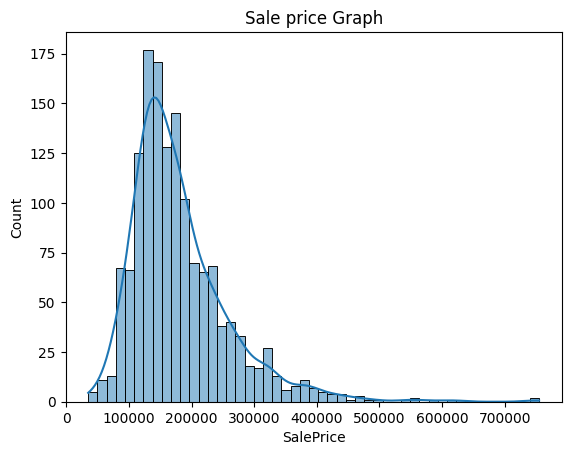

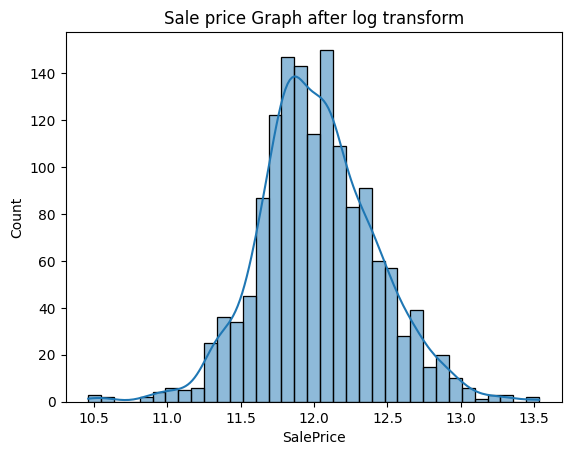

In [31]:
sns.histplot(y, kde=True)
plt.title("Sale price Graph")
plt.show()

plt.title("Sale price Graph after log transform")
sns.histplot(np.log(y), kde=True)
plt.show()

In [32]:
y_log = np.log(y)
X_train, X_val, y_train, y_val = train_test_split(X, y_log, test_size=0.2, random_state=42)

In [33]:
X_train.head()

,MSSubClass,MSZoning,LotFrontage,LotArea,Alley,LotShape,LandContour,LotConfig,LandSlope,Neighborhood,...,TotalSF,TotalBath,TotalPorchSF,HouseAge,RemodAge,IsRemodeled,HasGarage,HasBsmt,Has2ndFloor,HasFireplace
254,20,RL,70.0,8400,None,Reg,Lvl,Inside,Gtl,NAmes,...,2628,2.0,250,53,53,0,1,1,0,0
1066,60,RL,59.0,7837,None,IR1,Lvl,Inside,Gtl,Gilbert,...,2370,2.5,40,16,15,1,1,1,1,1
865,20,RL,NaN,8750,None,IR1,Lvl,Inside,Gtl,NAmes,...,2004,2.0,0,39,39,0,1,1,0,0
799,50,RL,60.0,7200,None,Reg,Lvl,Corner,Gtl,SWISU,...,2499,2.5,264,70,57,1,1,1,1,1
380,50,RL,50.0,5000,Pave,Reg,Lvl,Inside,Gtl,SWISU,...,2717,2.0,242,86,60,1,1,1,1,1


In [34]:
print(type(X_train), type(y_train))
from sklearn import set_config
set_config(transform_output='pandas')

<class 'pandas.core.frame.DataFrame'> <class 'pandas.core.series.Series'>


## Model Training Pipeline, Comparing Various Models with hyperparameter tuning

In [35]:
pipeline = Pipeline(steps=[
    ('preprocessing', preprocessing),
    ('model', LinearRegression())
])

pipeline.fit(X_train, y_train)

,steps,"[('preprocessing', ...), ('model', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('numeric_trnf', ...), ('skew_trnf', ...), ...]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [36]:
print("Linear Model")
y_pred = pipeline.predict(X_val)

print("Mean Squared Error :" , mean_squared_error(np.exp(y_val), np.exp(y_pred)))
print("Mean ABS Error :",  mean_absolute_error(np.exp(y_val), np.exp(y_pred)))
print("R2 Score :",  r2_score(y_val, y_pred))

print("Pipeline Score on Train set",pipeline.score(X_train, y_train), "\nPipeline Score on Validation set",pipeline.score(X_val, y_val)) 


Linear Model
Mean Squared Error : 451467469.96249026
Mean ABS Error : 15074.15397485139
R2 Score : 0.8933445762637036
Pipeline Score on Train set 0.9437378121371823 
Pipeline Score on Validation set 0.8933445762637036


In [37]:
models = {
    'Support Vector Machine' : SVR(kernel='poly', degree=2),
    'Decision Tree' : DecisionTreeRegressor(max_depth=6, random_state=42),
    'Random Forest' : RandomForestRegressor(max_depth=6, max_features=0.5,random_state=42, n_jobs=-1),
    'Ridge Regression' : Ridge(alpha=0.1, random_state=42),
    'Lasso Regression' : Lasso(alpha=0.001, max_iter=900, random_state=42),
    'Elastic Net' : ElasticNet(alpha=0.01, l1_ratio=0.6, random_state=42),
    'XG Boost' : XGBRegressor( n_estimators=500, 
                              eta=0.01, 
                              max_depth=4, 
                              subsample=0.8, 
                              colsample_bytree=0.8, 
                              reg_alpha=0.1, 
                              reg_lambda=1.0, 
                              tree_method='hist', 
                              random_state=42, 
                              device='cpu'),
    }

In [38]:
for name, m in models.items():   
    pipeline = Pipeline(steps=[
        ('preprocessing', preprocessing),
        ('model', m)
    ])

    pipeline.fit(X_train, y_train)

    y_pred = pipeline.predict(X_val)

    print(name)
    print("Mean Squared Error :" , mean_squared_error(np.exp(y_val), np.exp(y_pred)))
    print("Mean ABS Error :",  mean_absolute_error(np.exp(y_val), np.exp(y_pred)))
    print("R2 Score :",  r2_score(y_val, y_pred))
    print("Pipeline Score on Train set",pipeline.score(X_train, y_train), "\nPipeline Score on Validation set",pipeline.score(X_val, y_val)) 
    print("\n\n")

Support Vector Machine
Mean Squared Error : 412275517.18381816
Mean ABS Error : 14926.34810654178
R2 Score : 0.9112925599383582
Pipeline Score on Train set 0.9569002503789357 
Pipeline Score on Validation set 0.9112925599383582



Decision Tree
Mean Squared Error : 1582290587.8258874
Mean ABS Error : 25283.299649566357
R2 Score : 0.7507813627366333
Pipeline Score on Train set 0.9056286621946342 
Pipeline Score on Validation set 0.7507813627366333



Random Forest
Mean Squared Error : 569073152.7813963
Mean ABS Error : 17045.74817605293
R2 Score : 0.866910370973353
Pipeline Score on Train set 0.9374607446168883 
Pipeline Score on Validation set 0.8669103709733528



Ridge Regression
Mean Squared Error : 439581931.8860561
Mean ABS Error : 14964.533456478242
R2 Score : 0.8982852528794641
Pipeline Score on Train set 0.9436196777841066 
Pipeline Score on Validation set 0.8982852528794641



Lasso Regression
Mean Squared Error : 365427296.5149607
Mean ABS Error : 13900.154865399947
R2 Score 

In [39]:
feature_names = pipeline.named_steps['preprocessing'].get_feature_names_out()
coef_df = pd.DataFrame({
    'Feature': feature_names,
    'lasso_coef' : models['Lasso Regression'].coef_

})

coef_df.reindex(coef_df['lasso_coef'].abs().sort_values(ascending=False).index).head(5)

,Feature,lasso_coef
32,skew_trnf__GrLivArea,0.112387
207,cat_trnf__ohe__SaleType_New,0.080687
86,cat_trnf__ohe__Neighborhood_Crawfor,0.071461
0,numeric_trnf__OverallQual,0.071184
99,cat_trnf__ohe__Neighborhood_StoneBr,0.065897


In [40]:
coef_df.reindex(coef_df['lasso_coef'].abs().sort_values(ascending=False).index).tail(20)

,Feature,lasso_coef
185,cat_trnf__ohe__GarageType_Attchd,-0.0
186,cat_trnf__ohe__GarageType_BuiltIn,0.0
187,cat_trnf__ohe__GarageType_Detchd,0.0
182,cat_trnf__ohe__Functional_Min2,-0.0
197,cat_trnf__ohe__GarageCond_infrequent_sklearn,0.0
196,cat_trnf__ohe__GarageCond_TA,0.0
195,cat_trnf__ohe__GarageCond_None,-0.0
194,cat_trnf__ohe__GarageCond_Fa,-0.0
193,cat_trnf__ohe__GarageFinish_Unf,-0.0
192,cat_trnf__ohe__GarageFinish_RFn,-0.0


## Top 3 Best Models:
- Xgboost
- Support Vector Machine
- Ridge Regression
***
Linear Models are doing better than tree model in this dataset


In [41]:
from sklearn.model_selection import cross_val_score
kf = KFold(n_splits=5, shuffle=True, random_state=42)
models['Linear Regression'] = LinearRegression()

rows = []
for name, m in models.items():
    pipe = Pipeline([('preprocessing', preprocessing), ('model', m)])
    s = cross_val_score(pipe, X_train, y_train, cv=kf,
                        scoring='neg_root_mean_squared_error', n_jobs=-1)
    rows.append({'model': name, 'cv_rmse_log': -s.mean(), 'std': s.std()})
cv_table = pd.DataFrame(rows).sort_values('cv_rmse_log')
cv_table


,model,cv_rmse_log,std
4,Lasso Regression,0.114540,0.007467
3,Ridge Regression,0.116741,0.008152
7,Linear Regression,0.116938,0.007897
0,Support Vector Machine,0.118285,0.006350
6,XG Boost,0.123765,0.012115
5,Elastic Net,0.125552,0.009772
2,Random Forest,0.140540,0.013552
1,Decision Tree,0.196334,0.010087


In [42]:
ridge_pipe = Pipeline(steps=[
    ('preprocessing', preprocessing),
    ('model', Ridge(random_state=42))
])

params = {'model__alpha' : [ 0.1, 1.0, 10, 15, 20, 25, 28, 30]}

ridge_grid = GridSearchCV(estimator=ridge_pipe,
                          param_grid=params,
                          cv=kf,
                          scoring='neg_root_mean_squared_error',
                          n_jobs=-1
                          )

ridge_grid.fit(X_train, y_train)
print("Ridge Best Score:", ridge_grid.best_score_)
print("Ridge Best Params:", ridge_grid.best_params_)

Ridge Best Score: -0.11336516334247397
Ridge Best Params: {'model__alpha': 25}


In [43]:
from scipy.stats import uniform, randint
svr_pipeline = Pipeline(steps=[
    ('preprocessing', preprocessing),
    ('model', SVR())
])

svr_params = {'model__kernel' : ['rbf', 'poly'],
              'model__C' : uniform(0.1, 50),
              'model__gamma' : ['scale', 'auto'],
              'model__degree' : [2, 3]}

In [44]:
svr_search = RandomizedSearchCV(
    estimator=svr_pipeline,
    param_distributions=svr_params,
    cv= kf,
    n_iter=20,
    scoring='neg_root_mean_squared_error',
    random_state=42,
    n_jobs=-1
)

svr_search.fit(X_train, y_train)
print("SVM Best Score:", svr_search.best_score_)
print("SVM Best Params:", svr_search.best_params_)

SVM Best Score: -0.115723674564769
SVM Best Params: {'model__C': np.float64(0.7632480579933264), 'model__degree': 2, 'model__gamma': 'auto', 'model__kernel': 'poly'}


In [ ]:
xgb_pipeline = Pipeline(steps=[
    ('preprocessing', preprocessing),
    ('model', XGBRegressor(tree_method='hist', device='cpu', random_state=42))
])

xgb_params = {
    'model__n_estimators': randint(200, 1000),
    'model__max_depth' : randint(2, 8),
    'model__learning_rate' : uniform(0.01, 0.14),
    'model__subsample' : uniform(0.6, 0.4),
    'model__colsample_bytree' : uniform(0.6, 0.4)
}

xgb_search = RandomizedSearchCV(
    estimator=xgb_pipeline,
    param_distributions=xgb_params,
    n_iter=25,
    cv=kf,
    scoring='neg_root_mean_squared_error',
    random_state=42,
    n_jobs=-1
)

xgb_search.fit(X_train, y_train)
print("XGB Best Score:", xgb_search.best_score_)
print("XGB Best Params:", xgb_search.best_params_)

In [ ]:
print("Ridge Score on Validation Set : ", ridge_grid.score(X_val, y_val))
print("SVR Score on Validation Set : ", svr_search.score(X_val, y_val))
print("XGBoost Score on Validation Set : ", xgb_search.score(X_val, y_val))

Ridge Score on Validation Set :  -0.1185228432589574
SVR Score on Validation Set :  -0.1220743067332113
XGBoost Score on Validation Set :  -0.12365139929324598


In [ ]:
def search(est, grid, name):
    pipe = Pipeline([('preprocessing', preprocessing), ('model', est)])
    g = GridSearchCV(pipe, grid, cv=kf, scoring='neg_root_mean_squared_error', n_jobs=-1)
    g.fit(X_train, y_train)
    print(name, -g.best_score_, g.best_params_)
    return g

ridge_g = search(Ridge(), {'model__alpha': [1, 10, 20, 50, 100, 200, 500]}, 'Ridge')
lasso_g = search(Lasso(max_iter=10000), {'model__alpha': np.logspace(-4, -1, 12)}, 'Lasso')
enet_g  = search(ElasticNet(max_iter=10000),
                 {'model__alpha': np.logspace(-4, -1, 8),
                  'model__l1_ratio': [0.2, 0.5, 0.8]}, 'ElasticNet')

Ridge 0.11337758053248795 {'model__alpha': 20}
Lasso 0.11392852225716384 {'model__alpha': np.float64(0.0006579332246575682)}
ElasticNet 0.11404933571636952 {'model__alpha': np.float64(0.0007196856730011522), 'model__l1_ratio': 0.8}


In [ ]:
tuned = pd.DataFrame({
    'model': ['Ridge', 'Lasso', 'ElasticNet', 'SVR', 'XGBoost'],
    'cv_rmse_log': [-ridge_g.best_score_, -lasso_g.best_score_, -enet_g.best_score_,
                    -svr_search.best_score_, -xgb_search.best_score_]
}).sort_values('cv_rmse_log')

In [ ]:
tuned

,model,cv_rmse_log
0,Ridge,0.113378
1,Lasso,0.113929
2,ElasticNet,0.114049
3,SVR,0.115724
4,XGBoost,0.116407


In [ ]:
best_model = ridge_g.best_estimator_

In [ ]:
ridge_g = search(Ridge(), {'model__alpha': [5, 10, 15, 20, 25, 30, 40, 50]}, 'Ridge')

Ridge 0.11336516334247397 {'model__alpha': 25}


In [ ]:
pre = best_model.named_steps['preprocessing']
coefs = pd.Series(best_model.named_steps['model'].coef_, index=pre.get_feature_names_out())
coefs.reindex(coefs.abs().sort_values(ascending=False).index).head(10)

skew_trnf__GrLivArea                   0.065248
numeric_trnf__OverallQual              0.061048
cat_trnf__ohe__Neighborhood_StoneBr    0.058934
cat_trnf__ohe__Neighborhood_Crawfor    0.056398
cat_trnf__ohe__Exterior1st_BrkFace     0.047457
cat_trnf__ohe__Functional_Typ          0.046011
numeric_trnf__OverallCond              0.045409
cat_trnf__ohe__SaleType_New            0.038055
cat_trnf__ohe__Neighborhood_Gilbert   -0.037610
skew_trnf__TotalSF                     0.036687
dtype: float64

RMSE log: 0.11862811201536988
RMSE $:   19470.109822082795
MAE $:    14111.510133727748
R2:       0.9165218868356617


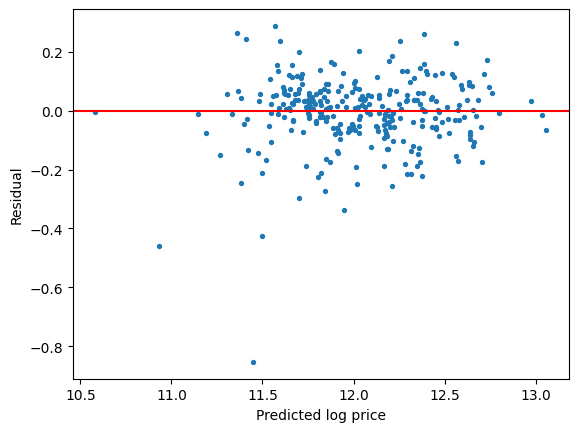

,actual,pred,abs_err,Neighborhood,OverallQual,GrLivArea,SaleCondition
608,359100.0,285257.305765,73842.694235,Crawfor,8,3194,Alloca
218,311500.0,239816.632273,71683.367727,Crawfor,7,1954,Normal
231,403000.0,338998.231234,64001.768766,NoRidge,8,2794,Normal
747,265979.0,209685.595977,56293.404023,OldTown,7,2640,Normal
30,40000.0,93891.112340,53891.112340,IDOTRR,4,1317,Normal
261,276000.0,329157.476909,53157.476909,CollgCr,8,2574,Partial
1322,190000.0,236947.921651,46947.921651,NoRidge,7,1923,Normal
1344,155835.0,201512.878202,45677.878202,CollgCr,7,1456,Partial
70,244000.0,289296.304449,45296.304449,NAmes,7,2223,Normal
728,110000.0,154409.369954,44409.369954,NAmes,5,1776,Abnorml


In [ ]:
pred = best_model.predict(X_val)          
print('RMSE log:', mean_squared_error(y_val, pred) ** 0.5)
print('RMSE $:  ', mean_squared_error(np.exp(y_val), np.exp(pred)) ** 0.5)
print('MAE $:   ', mean_absolute_error(np.exp(y_val), np.exp(pred)))
print('R2:      ', r2_score(y_val, pred))

plt.scatter(pred, y_val - pred, s=8); plt.axhline(0, color='r')
plt.xlabel('Predicted log price'); plt.ylabel('Residual'); plt.show()

err = pd.DataFrame({'actual': np.exp(y_val), 'pred': np.exp(pred)})
err['abs_err'] = (err['actual'] - err['pred']).abs()
err.sort_values('abs_err', ascending=False).head(10).join(
    X_val[['Neighborhood', 'OverallQual', 'GrLivArea', 'SaleCondition']])

Results. With 5-fold CV on log price, regularized linear models were best: Lasso 0.1145 and Ridge 0.1167 untuned. After tuning, all five models landed within 0.003 of each other (Ridge 0.1134 to XGBoost 0.1164), which is within fold-to-fold noise (about 0.008), so I chose Ridge as the simplest and best model. Tuning helped ElasticNet (0.1256 to 0.1140) and XGBoost (0.1238 to 0.1164) the most, because their hand-set values were poor. Trees did not beat linear models: the dataset is small (about 1,170 training rows) and log price is close to an additive function of the features.

What drives price. Living area (GrLivArea) and overall quality are the strongest features: one standard deviation more of either is worth roughly +6 to 7% in price. Neighborhood matters a lot (StoneBr and Crawfor carry a premium, Gilbert a discount), and newly built homes (SaleType_New) sell for more.

In [ ]:
from sklearn.base import clone
import joblib
final = clone(best_model).fit(X, y_log)
joblib.dump(final, 'house_price_pipeline.joblib')

NameError: name 'best_model' is not defined

In [ ]:
print(type(final))
print(final.named_steps.keys())
print(type(final.named_steps['model']))

NameError: name 'final' is not defined